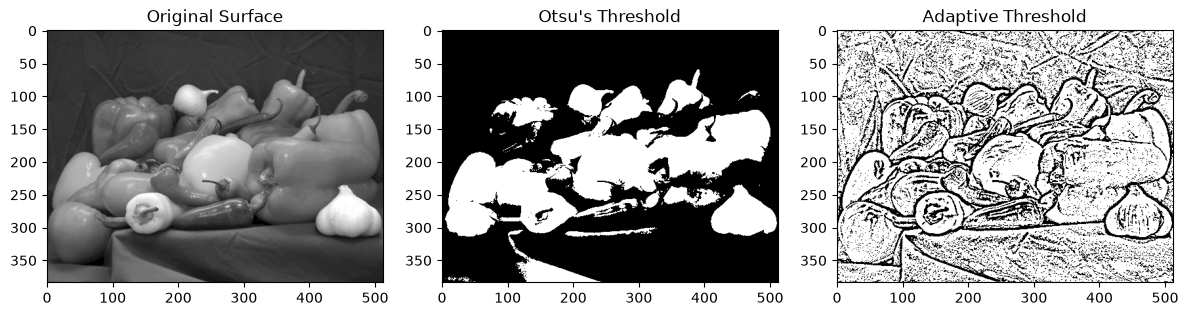

In [1]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('peppers.png', cv2.IMREAD_GRAYSCALE)

_, otsu_thresh = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)


adaptive_thresh = cv2.adaptiveThreshold(
    img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
)

# 4. Display the results
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Original Surface')
plt.subplot(1, 3, 2), plt.imshow(otsu_thresh, cmap='gray'), plt.title("Otsu's Threshold")
plt.subplot(1, 3, 3), plt.imshow(adaptive_thresh, cmap='gray'), plt.title('Adaptive Threshold')
plt.tight_layout()
plt.show()


Otsu Threshold Value: 108


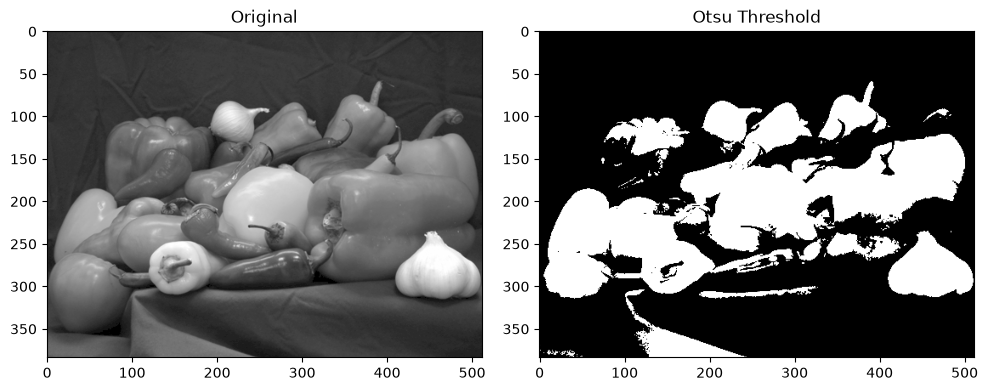

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Load image
img = cv2.imread('peppers.png', cv2.IMREAD_GRAYSCALE)
h, w = img.shape

# 1. Compute histogram manually
hist = np.zeros(256)
for i in range(h):
    for j in range(w):
        val = img[i, j]
        hist[val] = hist[val] + 1

# 2. Find best threshold
best_thresh = 0
max_variance = 0.0
total_pixels = h * w

for t in range(256):
    # Background stats
    weight_b = 0.0
    sum_b = 0.0
    for i in range(t):
        weight_b = weight_b + hist[i]
        sum_b = sum_b + (i * hist[i])
        
    if weight_b == 0:
        continue
    mean_b = sum_b / weight_b

    # Foreground stats
    weight_f = 0.0
    sum_f = 0.0
    for i in range(t, 256):
        weight_f = weight_f + hist[i]
        sum_f = sum_f + (i * hist[i])
        
    if weight_f == 0:
        break
    mean_f = sum_f / weight_f

    # Between-class variance
    variance = weight_b * weight_f * ((mean_b - mean_f) ** 2)

    if variance > max_variance:
        max_variance = variance
        best_thresh = t

print("Otsu Threshold Value:", best_thresh)

# 3. Create binary image
otsu_thresh = np.zeros_like(img)
for i in range(h):
    for j in range(w):
        if img[i, j] > best_thresh:
            otsu_thresh[i, j] = 255

# 4. Display output
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(1, 2, 2), plt.imshow(otsu_thresh, cmap='gray'), plt.title('Otsu Threshold')
plt.tight_layout()
plt.show()
